In [49]:

from adabmDCA.fasta import import_from_fasta, decode_sequence, write_fasta
from adabmDCA.sampling import gibbs_sampling
from adabmDCA.statmech import compute_energy
from tqdm.notebook import tqdm

import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns
import time
import RNA
import torch

from concurrent.futures import ProcessPoolExecutor
from functools import partial

# use latex and font size 14
plt.rc('text', usetex=True)
plt.rc('font', size=14)

tokens = "ACGU-"

### ViennaRNA functions

In [50]:
def compute_bpp_matrix(sequence):
    """
    Compute the base-pairing probability (bpp) matrix via ViennaRNA.

    Parameters
    ----------
    sequence : str
        RNA sequence (T già convertiti in U se presenti gap).

    Returns
    -------
    bpp : np.ndarray, shape (L, L)
        Matrice simmetrica delle probabilità di appaiamento (L = len(sequence)).
    """
    fc = RNA.fold_compound(sequence)
    propensity, ensemble_energy = fc.pf()
    basepair_probs = fc.bpp()  # nested list, 1-based

    L = len(sequence)
    bpp = np.zeros((L, L), dtype=float)
    for i in range(1, L+1):
        for j in range(1, L+1):
            bpp[i-1, j-1] = basepair_probs[i][j]
    return bpp


def dot_bracket_to_ss_matrix(ss):
    """
    Convert a dot-bracket string into a binary contact matrix.

    Parameters
    ----------
    ss : str
        Notazione secondaria “dot-bracket”.

    Returns
    -------
    cm : np.ndarray, shape (L, L)
        Matrice binaria con cm[i,j]=1 se i e j sono appaiati nella struttura.
    """
    L = len(ss)
    cm = np.zeros((L, L), dtype=int)
    stack_round = []  # for (
    stack_square = []  # for [
    stack_angle = []  # for <
    stack_curly = []  # for {
    for pos, c in enumerate(ss):
        if c == '(':
            stack_round.append(pos)
        elif c == '[':
            stack_square.append(pos)
        elif c == '<':
            stack_angle.append(pos)
        elif c == '{':
            stack_curly.append(pos)
        elif c == ')':
            if stack_round:
                i = stack_round.pop()
                cm[i, pos] = cm[pos, i] = 1
        elif c == ']':
            if stack_square:
                i = stack_square.pop()
                cm[i, pos] = cm[pos, i] = 1
        elif c == '>':
            if stack_angle:
                i = stack_angle.pop()
                cm[i, pos] = cm[pos, i] = 1
        elif c == '}':
            if stack_curly:
                i = stack_curly.pop()
                cm[i, pos] = cm[pos, i] = 1
    return cm



def _bpp_score_for_sequence(seq, cm):
    seq = seq.upper().replace('T', 'U')
    bpp = compute_bpp_matrix(seq)
    return float((bpp * cm).sum())

def compute_bpp_scores(sequences_one_hot, dot_bracket, num_workers=4):
    sequences_v = torch.argmax(sequences_one_hot, dim=-1)
    sequences = ["GUG"+ "".join(tokens[i] for i in sequence) + "G" for sequence in sequences_v]

    """
    Compute BPP scores and gap violations for a list of sequences given a dot-bracket structure.

    Args:
        sequences (list of str): List of RNA sequences (strings with 'U' instead of 'T').
        dot_bracket (str): Dot-bracket string representing the structure.
        num_workers (int): Number of processes to parallelize over.

    Returns:
        bpp_scores (list of float): BPP scores for each sequence.
        gap_violations (int): Number of gap violations across all sequences.
    """
    # Convert dot-bracket to structure matrix once
    cm = dot_bracket_to_ss_matrix(dot_bracket)

    # Use process pool to parallelize computation
    with ProcessPoolExecutor(max_workers=num_workers) as executor:
        bpp_scores = list(executor.map(partial(_bpp_score_for_sequence, cm=cm), sequences))

    return bpp_scores

In [52]:
def metropolis(energy_final, energy_initial):
    """
    Vectorized Metropolis acceptance function.
    Args:
        energy_final: (Tensor) Ending state energies, shape [batch_size]
        energy_initial: (Tensor) Starting state energies, shape [batch_size]
    Returns:
        accepted_mask: (Tensor[bool]) Mask of accepted proposals, shape [batch_size]
    """
    delta = energy_final - energy_initial
    prob = torch.exp(-delta)
    rand = torch.rand_like(prob)
    accepted_mask = rand < prob
    return accepted_mask



def hamming_distance_onehot(seq_batch, ref):
    """
    Compute Hamming distance between each sequence in seq_batch and the reference sequence.
    
    Args:
        seq_batch (torch.Tensor): One-hot encoded sequences, shape (N, L, q)
        ref (torch.Tensor): One-hot encoded reference sequence, shape (L, q)
    
    Returns:
        torch.Tensor: Hamming distances, shape (N,)
    """
    # Expand ref to (1, L, q) for broadcasting
    ref_exp = ref.unsqueeze(0)  # (1, L, q)
    # Find positions where sequences differ
    diff = (seq_batch != ref_exp).any(dim=-1)  # (N, L), True where differ
    # Sum the differences along the sequence length
    hamming = diff.sum(dim=-1)  # (N,)
    return hamming

### Import data

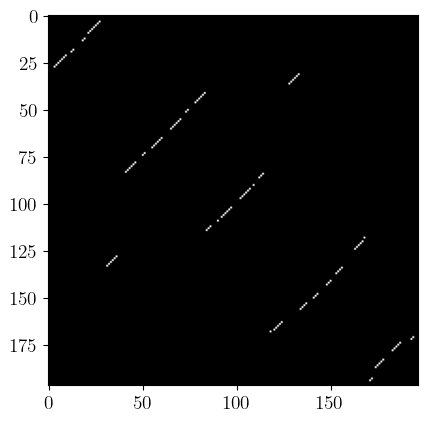

In [53]:
dot_bracket_with_pk = "...(((((((..((....)).)))))))...((((((....((((((...((...((((((....))))))..))...))))))(((...(.((((((....)))))).)..)))...[.[[[[[...))))))((((...(((....)))..))))......]]]]]]..((.(((((....))))).....)).."

ss_matrix = dot_bracket_to_ss_matrix(dot_bracket_with_pk)
plt.imshow(ss_matrix, cmap='gray')
plt.show()

In [54]:
# Load CSV into a pandas DataFrame
csv_path = "../Group_I_Intron/Matching_Data.csv"  # Replace with your actual CSV file path
df = pd.read_csv(csv_path)
df.head()

,names,activities_lowT,activities_highT,distances,sequences,DCA,SB
0,dca_f_mutations_129,-1.316208,-2.724580,55,GUGCCUUUCGACAGGAAACUUCGAAAGGAAUCCUGUCAAAUUCGGC...,37.074856,6.852815
1,dca_f_mutations_261,-2.664200,-999.000000,60,GUGCACUUUGUCGGGUUGCCGCAGAGUGAAUGUGGUCAAAUUCAAG...,33.076924,4.896689
2,dca_f_mutations_7,-2.736124,-999.000000,55,GUGCACUCAGCCGGGAAGCCGCAUAGUGGAUGUUCUCAAAUUCGGU...,28.189787,5.859439
3,dca_f_sequenza_1,-0.048592,1.969441,5,GUGCCUUUCGCCGGGAAACCACGAAAGGGAUGGUGUCAAAUUCGGC...,0.570879,5.453645
4,dca_f_sequenza_10,0.261965,1.722767,5,GUGCCUUGCGCCGGGAAACCACGCAAGGGAUGGUGUCAAAUUCGGC...,-0.357110,5.515907


In [55]:
path_data = "../Group_I_Intron/sequences.fasta"
path_sb = "../Group_I_Intron/bpp_scores.txt"
path_energy = "../Group_I_Intron/sequences_en.txt"

SB2 = np.loadtxt(path_sb)
DCA2 = np.loadtxt(path_energy)
nat_headers, nat_sequences = import_from_fasta(path_data, tokens=tokens)
nat_sequences = nat_sequences[:,3:-1] # Remove the added GUG and G

In [56]:
# Load model
path_model = "../Group_I_Intron/modello_FC_T=1"
params_np = np.load(path_model)
params = {
    'bias': torch.tensor(params_np['h_local'], dtype=torch.float32, device='cuda').contiguous(),
    'coupling_matrix': torch.tensor(params_np['couplings'], dtype=torch.float32, device='cuda').contiguous()
}

In [57]:
# Load wild type sequences to mutate
path_wt = "./WTs_to_thermo_fix.fasta"
wt_headers, wt_sequences_enc = import_from_fasta(path_wt, tokens=tokens)
wt_sequences_enc = wt_sequences_enc[:,3:-1]  # Remove the added GUG and G
wt_sequences = torch.nn.functional.one_hot(torch.tensor(wt_sequences_enc), num_classes=5).float().to('cuda')

In [58]:
path_convert_names = "../lore/WTs_to_thermo_fix_mapping_names.txt"
convert_names = {}
with open(path_convert_names, 'r') as f:
    for line in f:
        parts = line.strip().split(' ')
        if len(parts) == 2:
            convert_names[parts[1]] = parts[0]
print(convert_names)

{'wt_1': 'dca_f_sequenza_682', 'wt_2': 'dca_f_sequenza_689', 'wt_3': 'dca_f_sequenza_698', 'wt_4': 'dca_f_sequenza_707', 'wt_5': 'dca_f_sequenza_739', 'wt_6': 'dca_f_sequenza_762', 'wt_7': 'dca_f_sequenza_794', 'wt_8': 'dca_f_sequenza_799', 'wt_9': 'old_dca_619_20_30', 'wt_10': 'old_dca_953_30_40'}


In [60]:
# select a WT sequence
idx_wt = 3
wt_seq = wt_sequences[idx_wt:idx_wt+1]  # Shape (1, L, q)
wt_header = wt_headers[idx_wt]

wt_energy = compute_energy(wt_seq, params=params).item()
wt_sb_score = compute_bpp_scores(torch.cat([wt_seq, wt_seq], dim=0), dot_bracket_with_pk, num_workers=1)[0]

# find the corresponding row in the dataframe
row = df[df["names"] == convert_names[wt_header]]

print("Sequence name:", wt_header)
print("DCA score:", wt_energy)
print("SB score:", wt_sb_score)
print("Distance from Azoarcus:", row["distances"].values[0])
print("T = 37C activity:", row["activities_lowT"].values[0])
print("T = 60C activity:", row["activities_highT"].values[0])

Sequence name: wt_4
DCA score: 79.81021118164062
SB score: 1.304527028495677
Distance from Azoarcus: 25
T = 37C activity: -1.5837469900473664
T = 60C activity: -999.0


In [61]:
n_slow_steps = 20
n_fast_sweeps = 10
n_seqs = 30000


beta_power = 1 / 0.8
is_power = 2.0
potential_power = -3.0

use_bpp_score = True

# Bias the parameters
params_mod = {k : v.clone() for k, v in params.items()}
params_mod['bias'] = params['bias'] * beta_power
params_mod['coupling_matrix'] = params['coupling_matrix'] * beta_power
params_mod['bias'] = params_mod['bias'] + wt_seq.squeeze(0) * is_power

chains_0 = wt_seq.repeat(n_seqs, 1, 1)
slow_score_0 = torch.tensor(compute_bpp_scores(chains_0, dot_bracket_with_pk, 20))
start_time = time.time()
gibbs_sampling = torch.jit.script(gibbs_sampling)

pbar = tqdm(range(n_slow_steps))
for i in range(n_slow_steps):
    pbar.update(1)
    chains_1 = gibbs_sampling(chains_0, params_mod, nsweeps=n_fast_sweeps)
    if use_bpp_score:
        slow_score_1 = torch.tensor(compute_bpp_scores(chains_1, dot_bracket_with_pk, 20))
        accepted_mask = metropolis(-potential_power*slow_score_1, -potential_power*slow_score_0)
        chains_0[accepted_mask] = chains_1[accepted_mask]
        slow_score_0[accepted_mask] = slow_score_1[accepted_mask]
    else:
        chains_0 = chains_1

  0%|          | 0/20 [00:00<?, ?it/s]

In [62]:
sb_scores = slow_score_0.numpy()
dca_scores = compute_energy(chains_0, params=params).cpu().numpy()
headers_mut = [f"{wt_header}_mut_{i}" for i in range(n_seqs)]
distances = hamming_distance_onehot(chains_0, wt_seq.squeeze(0)).cpu().numpy()
mutants = decode_sequence(chains_0.cpu().numpy(), tokens=tokens)

# compute distance from Azoarcus
path_azo = "../Group_I_Intron/azo.seq"
azo_header, azo_sequence_enc = import_from_fasta(path_azo, tokens=tokens)
azo_sequence = torch.nn.functional.one_hot(torch.tensor(azo_sequence_enc), num_classes=5).float().to('cuda')
distances_azo = hamming_distance_onehot(chains_0, azo_sequence.squeeze(0)).cpu().numpy()

df_mut = pd.DataFrame({
    "DCA_score": dca_scores,
    "SB_score": sb_scores,
    "distance_from_WT": distances,
    "distance_from_Azoarcus": distances_azo,
    "sequence": mutants,
})

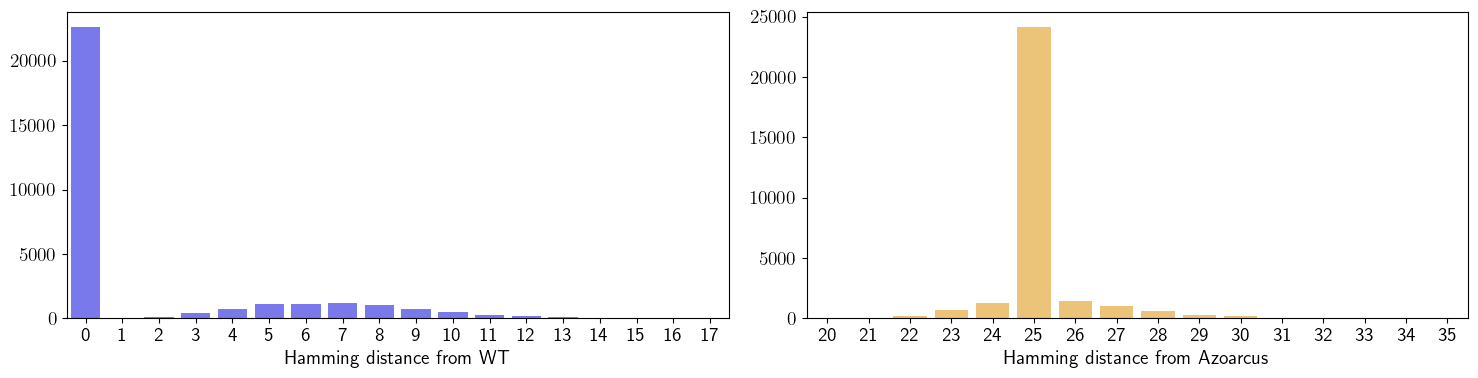

In [63]:
fig = plt.figure(figsize=(15,4))
fig.add_subplot(1,2,1)
u_dwt, u_cdwt = np.unique(df_mut["distance_from_WT"], return_counts=True)
sns.barplot(x=u_dwt, y=u_cdwt, color='blue', alpha=0.6)
plt.xlabel("Hamming distance from WT")
fig.add_subplot(1,2,2)
u_dazo, u_cdazo = np.unique(df_mut["distance_from_Azoarcus"], return_counts=True)
sns.barplot(x=u_dazo, y=u_cdazo, color='orange', alpha=0.6)
plt.xlabel("Hamming distance from Azoarcus")
plt.tight_layout()

In [64]:
min_dist = 5
max_dist = 10
df_filtered = df_mut[(df_mut["distance_from_WT"] >= min_dist) & (df_mut["distance_from_WT"] <= max_dist)]
print(f"Number of sequences with distance in [{min_dist}, {max_dist}]: {len(df_filtered)}")

Number of sequences with distance in [5, 10]: 5594


In [65]:
min_dist_azo = 25
max_dist_azo = 35
df_filtered = df_filtered[(df_filtered["distance_from_Azoarcus"] >= min_dist_azo) & (df_filtered["distance_from_Azoarcus"] <= max_dist_azo)]
print(f"Number of sequences with distance from Azoarcus in [{min_dist_azo}, {max_dist_azo}]: {len(df_filtered)}")

Number of sequences with distance from Azoarcus in [25, 35]: 4079


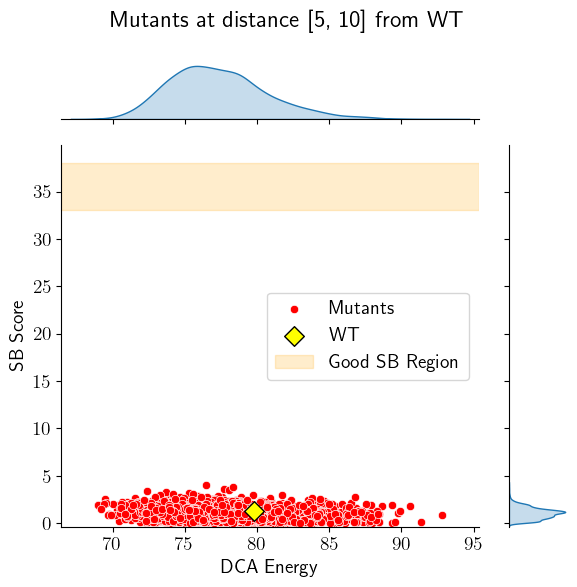

In [66]:
sb_good_threshold = 33

g = sns.jointplot(data=df_filtered, x="DCA_score", y="SB_score", kind="kde", fill=True, cmap="Blues")
# add scatter points and histograms
sns.scatterplot(data=df_filtered, x="DCA_score", y="SB_score", color='red', alpha=1.0, label="Mutants")
# visualize wild type point
plt.scatter(wt_energy, wt_sb_score, color='yellow', s=100, label='WT', edgecolors='black', marker='D')
# Horizontal line to indicate good SB score threshold
plt.axhspan(
    sb_good_threshold,
    sb_good_threshold + 5,
    color='orange',
    alpha=0.2,
    label='Good SB Region',
    zorder=0,
)
plt.xlabel('DCA Energy')
plt.ylabel('SB Score')
plt.legend()
g.fig.suptitle(f"Mutants at distance [{min_dist}, {max_dist}] from WT")
plt.tight_layout()


In [67]:
# filter for DCA energies below WT and SB score below threshold
sb_bad_threshold = 10
df_final = df_filtered[(df_filtered["DCA_score"] < wt_energy) & (df_filtered["SB_score"] < sb_bad_threshold)]
print(f"Number of sequences with DCA score below WT and SB score below threshold: {len(df_final)}")

Number of sequences with DCA score below WT and SB score below threshold: 3218


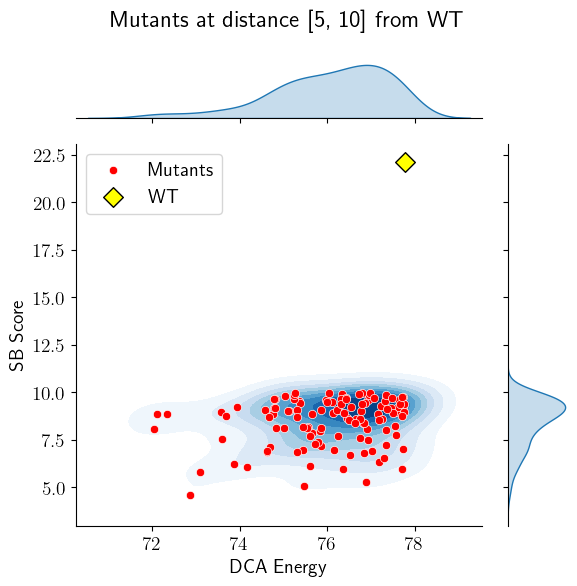

In [47]:
g = sns.jointplot(data=df_final, x="DCA_score", y="SB_score", kind="kde", fill=True, cmap="Blues")
# add scatter points and histograms
sns.scatterplot(data=df_final, x="DCA_score", y="SB_score", color='red', alpha=1.0, label="Mutants")
# visualize wild type point
plt.scatter(wt_energy, wt_sb_score, color='yellow', s=100, label='WT', edgecolors='black', marker='D')
plt.xlabel('DCA Energy')
plt.ylabel('SB Score')
plt.legend()
g.fig.suptitle(f"Mutants at distance [{min_dist}, {max_dist}] from WT")
plt.tight_layout()

In [48]:
final_headers = [f"{wt_header}_mut_lowDCA_lowSB_beta{beta_power:.2f}_sb{potential_power:.2f}_{i+1}" for i in range(len(df_final))]
final_sequences = df_final["sequence"].tolist()
write_fasta(
    f"{wt_header}_mutants_lowDCA_lowSB_beta{beta_power:.2f}_sb{potential_power:.2f}_integration.fasta",
    final_headers,
    final_sequences,
    tokens=tokens,
)

### Iterate over the wildtypes

In [10]:
n_slow_steps = 20
n_fast_sweeps = 10
n_seqs = 30000

beta_power = 1 / 0.8
is_power = 2.0
potential_power = -3.0

use_bpp_score = True
gibbs_sampling = torch.jit.script(gibbs_sampling)

for idx_wt in range(10):
    wt_seq = wt_sequences[idx_wt:idx_wt+1]  # Shape (1, L, q)
    wt_header = wt_headers[idx_wt]
    
    wt_energy = compute_energy(wt_seq, params=params).item()
    wt_sb_score = compute_bpp_scores(torch.cat([wt_seq, wt_seq], dim=0), dot_bracket_with_pk, num_workers=1)[0]
    
    # find the corresponding row in the dataframe
    row = df[df["names"] == convert_names[wt_header]]
    
    print("Sequence name:", wt_header)
    print("DCA score:", wt_energy)
    print("SB score:", wt_sb_score)
    print("Distance from Azoarcus:", row["distances"].values[0])
    print("T = 37C activity:", row["activities_lowT"].values[0])
    print("T = 60C activity:", row["activities_highT"].values[0])
    
    # Bias the parameters
    params_mod = {k : v.clone() for k, v in params.items()}
    params_mod['bias'] = params['bias'] * beta_power
    params_mod['coupling_matrix'] = params['coupling_matrix'] * beta_power
    params_mod['bias'] = params_mod['bias'] + wt_seq.squeeze(0) * is_power
    
    chains_0 = wt_seq.repeat(n_seqs, 1, 1)
    slow_score_0 = torch.tensor(compute_bpp_scores(chains_0, dot_bracket_with_pk, 20))
    start_time = time.time()
    gibbs_sampling = torch.jit.script(gibbs_sampling)
    
    pbar = tqdm(range(n_slow_steps))
    for i in range(n_slow_steps):
        pbar.update(1)
        chains_1 = gibbs_sampling(chains_0, params_mod, nsweeps=n_fast_sweeps)
        if use_bpp_score:
            slow_score_1 = torch.tensor(compute_bpp_scores(chains_1, dot_bracket_with_pk, 20))
            accepted_mask = metropolis(-potential_power*slow_score_1, -potential_power*slow_score_0)
            chains_0[accepted_mask] = chains_1[accepted_mask]
            slow_score_0[accepted_mask] = slow_score_1[accepted_mask]
        else:
            chains_0 = chains_1

    sb_scores = slow_score_0.numpy()
    dca_scores = compute_energy(chains_0, params=params).cpu().numpy()
    distances = hamming_distance_onehot(chains_0, wt_seq.squeeze(0)).cpu().numpy()
    mutants = decode_sequence(chains_0.cpu().numpy(), tokens=tokens)
    
    # compute distance from Azoarcus
    path_azo = "../Group_I_Intron/azo.seq"
    azo_header, azo_sequence_enc = import_from_fasta(path_azo, tokens=tokens)
    azo_sequence = torch.nn.functional.one_hot(torch.tensor(azo_sequence_enc), num_classes=5).float().to('cuda')
    distances_azo = hamming_distance_onehot(chains_0, azo_sequence.squeeze(0)).cpu().numpy()
    
    df_mut = pd.DataFrame({
        "DCA_score": dca_scores,
        "SB_score": sb_scores,
        "distance_from_WT": distances,
        "distance_from_Azoarcus": distances_azo,
        "sequence": mutants,
    })
    
    min_dist = 5
    max_dist = 10
    df_filtered = df_mut[(df_mut["distance_from_WT"] >= min_dist) & (df_mut["distance_from_WT"] <= max_dist)]
    print(f"Number of sequences with distance in [{min_dist}, {max_dist}]: {len(df_filtered)}")
    
    min_dist_azo = 25
    max_dist_azo = 30
    df_filtered = df_filtered[(df_filtered["distance_from_Azoarcus"] >= min_dist_azo) & (df_filtered["distance_from_Azoarcus"] <= max_dist_azo)]
    print(f"Number of sequences with distance from Azoarcus in [{min_dist_azo}, {max_dist_azo}]: {len(df_filtered)}")
    
    sb_good_threshold = 33
    # filter for DCA energies below WT and SB score below threshold
    sb_bad_threshold = 10
    df_final = df_filtered[(df_filtered["DCA_score"] < wt_energy) & (df_filtered["SB_score"] < sb_bad_threshold)]
    print(f"Number of sequences with DCA score below WT and SB score below threshold: {len(df_final)}")

    final_headers = [f"{wt_header}_mut_lowDCA_lowSB_beta{beta_power:.2f}_sb{potential_power:.2f}_{i+1}" for i in range(len(df_final))]
    final_sequences = df_final["sequence"].tolist()
    write_fasta(
        f"{wt_header}_mutants_lowDCA_lowSB_beta{beta_power:.2f}_sb{potential_power:.2f}.fasta",
        final_headers,
        final_sequences,
        tokens=tokens,
    )
    
    print("\n")
    

Sequence name: wt_1
DCA score: 82.28799438476562
SB score: 14.675348812220255
Distance from Azoarcus: 25
T = 37C activity: -1.6631183940578995
T = 60C activity: -999.0


  0%|          | 0/20 [00:00<?, ?it/s]

Number of sequences with distance in [5, 10]: 7650
Number of sequences with distance from Azoarcus in [25, 30]: 3502
Number of sequences with DCA score below WT and SB score below threshold: 446


Sequence name: wt_2
DCA score: 79.8155517578125
SB score: 10.896933032620414
Distance from Azoarcus: 25
T = 37C activity: -1.2325486734560251
T = 60C activity: -999.0


  0%|          | 0/20 [00:00<?, ?it/s]

Number of sequences with distance in [5, 10]: 10179
Number of sequences with distance from Azoarcus in [25, 30]: 4547
Number of sequences with DCA score below WT and SB score below threshold: 2056


Sequence name: wt_3
DCA score: 82.97982788085938
SB score: 21.760408719446133
Distance from Azoarcus: 25
T = 37C activity: -1.869807879448937
T = 60C activity: -999.0


  0%|          | 0/20 [00:00<?, ?it/s]

... (11 outputs left out)

  0%|          | 0/20 [00:00<?, ?it/s]

Number of sequences with distance in [5, 10]: 13985
Number of sequences with distance from Azoarcus in [25, 30]: 10127
Number of sequences with DCA score below WT and SB score below threshold: 194


Sequence name: wt_10
DCA score: 82.2752685546875
SB score: 22.258690912035767
Distance from Azoarcus: 30
T = 37C activity: -1.8746444307689487
T = 60C activity: -999.0


  0%|          | 0/20 [00:00<?, ?it/s]

Number of sequences with distance in [5, 10]: 18064
Number of sequences with distance from Azoarcus in [25, 30]: 8806
Number of sequences with DCA score below WT and SB score below threshold: 1427


